# 04 - Figures and tables

**Stage 4 of 4.** Reads the files saved by notebooks 02 and 03 and produces every figure and table used in the paper. Nothing is estimated here: the models are not refitted, so this notebook runs in a few seconds.

Outputs: `../figures/*.png` and `*.pdf` (six figures) and `../figures/table_main_results.csv` and `.tex`.

Run from the folder `code/` in a fresh kernel.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/processed/matches_model.csv.gz")
RESULTS = Path("../results")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

# Okabe-Ito colour-blind-safe palette
BLUE, ORANGE, GREEN, VERMILION, PURPLE, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#7f7f7f"

plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show()

SET_ORDER = ["rank", "rank+context", "rank+elo", "all", "all+elo"]
MODEL_LABEL = {"logreg": "Logistic regression", "knn": "k-NN", "gboost": "Gradient boosting"}
MODEL_COLOR = {"logreg": BLUE, "knn": ORANGE, "gboost": VERMILION}

table = pd.read_csv(DATA)
metrics = pd.read_csv(RESULTS / "test_metrics.csv")
print(f"{len(table):,} matches; test metrics rows: {len(metrics)}")

70,564 matches; test metrics rows: 16


## Figure 1. Upset rate against the ranking gap and against the Elo gap

Descriptive, no model. Matches from 2003 on (the Elo ratings need about three seasons to settle) are cut into ten equal-sized groups, once by the log ratio of the two ranks and once by the Elo difference. Group 1 is the closest match-up and group 10 the most one-sided. If a variable separates upsets well, the upset rate should fall steeply from group 1 to group 10.

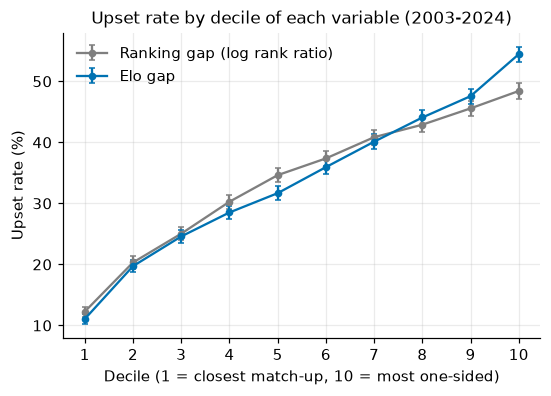

variable
Elo gap                         11.1% -> 54.4%
Ranking gap (log rank ratio)    12.3% -> 48.4%
Name: mean, dtype: object


In [2]:
d = table[table["year"] >= 2003].copy()
rows = []
for col, label in [("log_rank_ratio", "Ranking gap (log rank ratio)"), ("elo_diff", "Elo gap")]:
    # high value = favourite much stronger; reverse the decile number so 1 = closest match-up
    dec = pd.qcut(d[col], 10, labels=False, duplicates="drop")
    dec = dec.max() - dec + 1
    g = d.groupby(dec)["upset"].agg(["mean", "size"])
    g["se"] = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
    g["variable"] = label
    rows.append(g.reset_index(names="group"))
fig1 = pd.concat(rows)

fig, ax = plt.subplots(figsize=(5.6, 3.6))
for (name, g), colr in zip(fig1.groupby("variable", sort=False), [GREY, BLUE]):
    ax.errorbar(g["group"], g["mean"] * 100, yerr=1.96 * g["se"] * 100, marker="o", ms=4,
                capsize=2, color=colr, label=name)
ax.set_xlabel("Decile (1 = closest match-up, 10 = most one-sided)")
ax.set_ylabel("Upset rate (%)")
ax.set_xticks(range(1, 11))
ax.legend(frameon=False)
ax.set_title("Upset rate by decile of each variable (2003-2024)")
save(fig, "fig1_upset_rate_by_decile")
print(fig1.groupby("variable")["mean"].agg(lambda s: f"{s.iloc[0]:.1%} -> {s.iloc[-1]:.1%}"))

## Figure 2. Test AUC by feature set and model

Test period 2022-2024, models trained on 2000-2021. A coin flip gives 0.5.

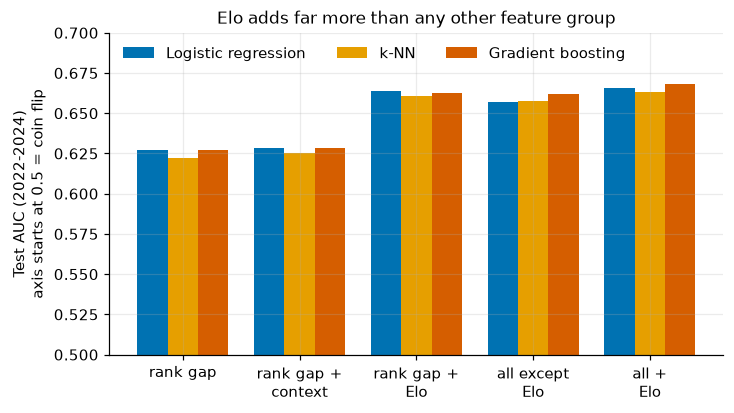

model         gboost     knn  logreg
features                            
rank          0.6271  0.6222  0.6275
rank+context  0.6287  0.6256  0.6282
rank+elo      0.6626  0.6609  0.6637
all           0.6622  0.6574  0.6573
all+elo       0.6681  0.6631  0.6658


In [3]:
m = metrics[metrics["features"].isin(SET_ORDER)]
piv = m.pivot(index="features", columns="model", values="auc").loc[SET_ORDER]

fig, ax = plt.subplots(figsize=(7.2, 3.8))
w = 0.26
x = np.arange(len(SET_ORDER))
for i, k in enumerate(["logreg", "knn", "gboost"]):
    ax.bar(x + (i - 1) * w, piv[k], w, color=MODEL_COLOR[k], label=MODEL_LABEL[k])
ax.set_xticks(x)
ax.set_xticklabels(["rank gap", "rank gap +\ncontext", "rank gap +\nElo", "all except\nElo", "all +\nElo"])
ax.set_ylim(0.5, 0.70)
ax.set_ylabel("Test AUC (2022-2024)\naxis starts at 0.5 = coin flip")
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Elo adds far more than any other feature group")
save(fig, "fig2_test_auc_by_feature_set")
print(piv.round(4))

## Figure 3. What drives the predictions (permutation importance)

Final model on all features including Elo (gradient boosting, test set). Each bar is the drop in AUC when one group of features is shuffled; the whiskers show the spread over repeated shuffles. Groups of correlated features share credit, so these are not additive effects.

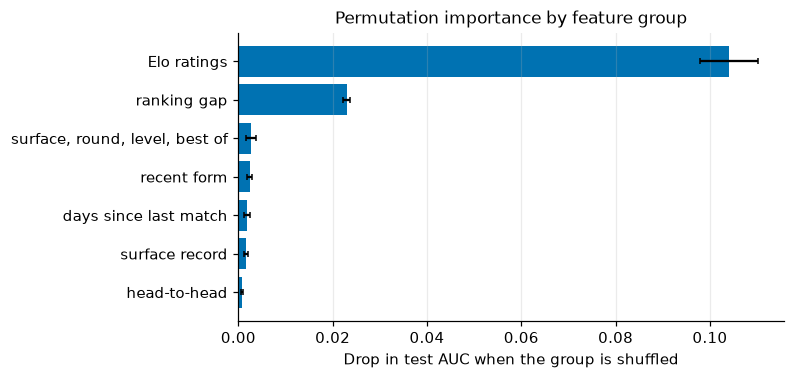

                         group  auc_drop_mean  auc_drop_std
                   Elo ratings         0.1041        0.0061
                   ranking gap         0.0230        0.0007
surface, round, level, best of         0.0026        0.0011
                   recent form         0.0024        0.0005
         days since last match         0.0019        0.0006
                surface record         0.0016        0.0004
                  head-to-head         0.0008        0.0002


In [4]:
imp = pd.read_csv(RESULTS / "permutation_importance.csv").sort_values("auc_drop_mean")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.barh(imp["group"], imp["auc_drop_mean"], xerr=imp["auc_drop_std"], color=BLUE, capsize=2)
ax.set_xlabel("Drop in test AUC when the group is shuffled")
ax.set_title("Permutation importance by feature group")
ax.grid(axis="y", visible=False)
save(fig, "fig3_permutation_importance")
print(imp.sort_values("auc_drop_mean", ascending=False).round(4).to_string(index=False))

## Figure 4. Calibration on the test set

Test predictions of the three models with all features including Elo, grouped into ten equal-sized bins of predicted upset probability. Points on the diagonal mean the predicted probabilities can be taken at face value.

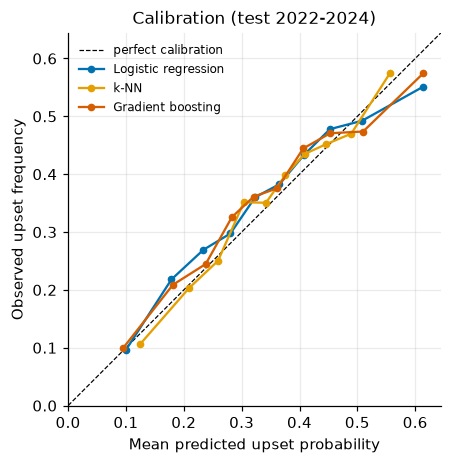

In [5]:
cal = pd.read_csv(RESULTS / "calibration.csv")
fig, ax = plt.subplots(figsize=(4.8, 4.4))
lim = max(cal["mean_predicted"].max(), cal["observed"].max()) + 0.03
ax.plot([0, lim], [0, lim], color="black", lw=0.8, ls="--", label="perfect calibration")
for k in ["logreg", "knn", "gboost"]:
    g = cal[cal["model"] == k]
    ax.plot(g["mean_predicted"], g["observed"], marker="o", ms=4, color=MODEL_COLOR[k], label=MODEL_LABEL[k])
ax.set_xlabel("Mean predicted upset probability")
ax.set_ylabel("Observed upset frequency")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Calibration (test 2022-2024)")
save(fig, "fig4_calibration")

## Figure 5. Stability over time

Left: validation AUC for each year from 2015 to 2021 (models trained on all earlier years). Right: test AUC for 2022-2024. Five specifications are shown: the ranking gap alone, the ranking gap with Elo, all non-Elo features, and all features with Elo (logistic regression and gradient boosting).

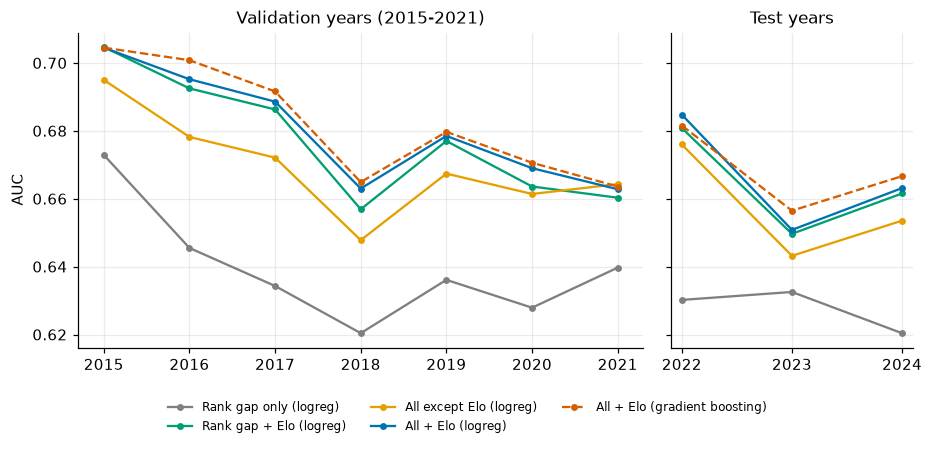

In [6]:
val = pd.read_csv(RESULTS / "auc_by_validation_year.csv")
val = val[val["year"].astype(str).str.fullmatch("[0-9]{4}")].copy()   # drop the summary row
val["year"] = val["year"].astype(int)
tby = pd.read_csv(RESULTS / "test_auc_by_year.csv")
specs = [  # label, validation column, (features, model) in the test file, colour, style
    ("Rank gap only (logreg)",         "rank logreg",       ("rank", "logreg"),      GREY,   "-"),
    ("Rank gap + Elo (logreg)",        "rank+elo logreg",   ("rank+elo", "logreg"),  GREEN,  "-"),
    ("All except Elo (logreg)",        "all logreg",        ("all", "logreg"),       ORANGE, "-"),
    ("All + Elo (logreg)",             "all+elo logreg",    ("all+elo", "logreg"),   BLUE,   "-"),
    ("All + Elo (gradient boosting)",  "all+elo gboost",    ("all+elo", "gboost"),   VERMILION, "--"),
]
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), sharey=True, gridspec_kw={"width_ratios": [7, 3]})
for label, vcol, key, colr, ls in specs:
    axes[0].plot(val["year"], val[vcol], marker="o", ms=3.5, color=colr, ls=ls, label=label)
    row = tby[(tby["features"] == key[0]) & (tby["model"] == key[1])].iloc[0]
    yrs = [2022, 2023, 2024]
    axes[1].plot(yrs, [row[str(y)] for y in yrs], marker="o", ms=3.5, color=colr, ls=ls)
axes[0].set_title("Validation years (2015-2021)")
axes[1].set_title("Test years")
axes[1].set_xticks([2022, 2023, 2024])
axes[0].set_ylabel("AUC")
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=8, loc="upper center",
           ncol=3, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout()
save(fig, "fig5_auc_by_year")

## Figure 6. Differences in test AUC with bootstrap intervals

Differences between pairs of specifications on the test set, with 95% bootstrap confidence intervals from 1,000 resamples (computed in notebook 03). An interval that includes zero means the difference cannot be told apart from noise.

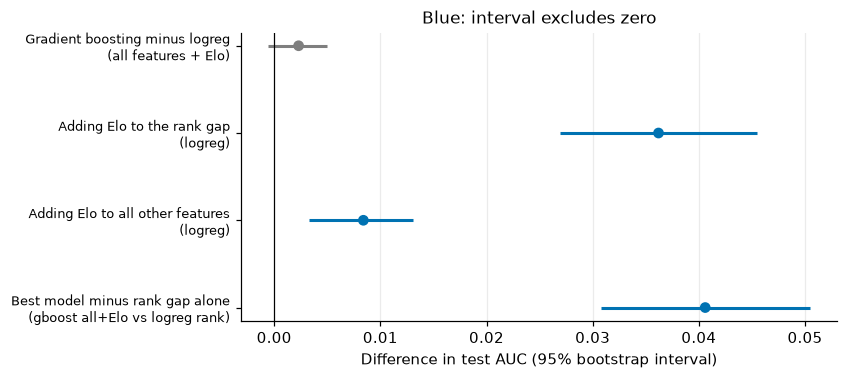

                                                      diff      lo      hi
Best model minus rank gap alone\n(gboost all+El...  0.0406  0.0308  0.0505
Adding Elo to all other features\n(logreg)          0.0084  0.0033  0.0131
Adding Elo to the rank gap\n(logreg)                0.0362  0.0269  0.0455
Gradient boosting minus logreg\n(all features +...  0.0023 -0.0006  0.0050


In [7]:
bs = pd.read_csv(RESULTS / "test_bootstrap.csv", index_col=0)["difference"]
pat = re.compile(r"([+-][0-9.]+)\s+95% CI \[([+-][0-9.]+), ([+-][0-9.]+)\]")
parsed = pd.DataFrame([[float(v) for v in pat.match(s).groups()] for s in bs], index=bs.index,
                      columns=["diff", "lo", "hi"])
LBL = {"AUC gboost - logreg (all+elo)": "Gradient boosting minus logreg\n(all features + Elo)",
       "AUC Elo effect on rank only (logreg)": "Adding Elo to the rank gap\n(logreg)",
       "AUC Elo effect on all features (logreg)": "Adding Elo to all other features\n(logreg)",
       "AUC all+elo gboost - rank logreg": "Best model minus rank gap alone\n(gboost all+Elo vs logreg rank)"}
parsed.index = [LBL.get(i, i) for i in parsed.index]
parsed = parsed.iloc[::-1]

fig, ax = plt.subplots(figsize=(7.0, 3.4))
yy = np.arange(len(parsed))
colors = [BLUE if (lo > 0 or hi < 0) else GREY for lo, hi in zip(parsed["lo"], parsed["hi"])]
ax.hlines(yy, parsed["lo"], parsed["hi"], color=colors, lw=2)
ax.scatter(parsed["diff"], yy, color=colors, zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(yy)
ax.set_yticklabels(parsed.index, fontsize=8.5)
ax.set_xlabel("Difference in test AUC (95% bootstrap interval)")
ax.set_title("Blue: interval excludes zero")
ax.grid(axis="y", visible=False)
save(fig, "fig6_bootstrap_differences")
print(parsed.round(4))

## Table. Main test results

All fifteen combinations of feature set and model on the test period, plus the naive baseline that always predicts "no upset". Precision, recall and F1 use the F1-optimal threshold picked on the out-of-fold validation predictions (never on the test set).

In [8]:
FS_NAME = {"rank": "Rank gap", "rank+context": "Rank gap + context", "rank+elo": "Rank gap + Elo",
           "all": "All except Elo", "all+elo": "All + Elo"}
tab = metrics[metrics["features"].isin(SET_ORDER)].copy()
tab["features"] = pd.Categorical(tab["features"], SET_ORDER, ordered=True)
tab["model"] = pd.Categorical(tab["model"], ["logreg", "knn", "gboost"], ordered=True)
tab = tab.sort_values(["features", "model"])
out = pd.DataFrame({
    "Features": tab["features"].map(FS_NAME).astype(str),
    "Model": tab["model"].map(MODEL_LABEL).astype(str),
    "AUC": tab["auc"].round(3), "Log loss": tab["log_loss"].round(3),
    "Accuracy": tab["accuracy"].round(3), "Precision": tab["precision"].round(3),
    "Recall": tab["recall"].round(3), "F1": tab["f1"].round(3),
})
base = metrics[metrics["features"] == "-"].iloc[0]
print(f"Naive baseline (always 'no upset'): accuracy {base['accuracy']:.3f}, AUC 0.500")
out.to_csv(FIG / "table_main_results.csv", index=False)
out.to_latex(FIG / "table_main_results.tex", index=False, float_format="%.3f")
out.to_string(index=False)

Naive baseline (always 'no upset'): accuracy 0.642, AUC 0.500


'          Features               Model   AUC  Log loss  Accuracy  Precision  Recall    F1\n          Rank gap Logistic regression 0.627     0.628     0.500      0.408   0.883 0.559\n          Rank gap                k-NN 0.622     0.630     0.509      0.412   0.866 0.558\n          Rank gap   Gradient boosting 0.627     0.628     0.508      0.411   0.866 0.558\nRank gap + context Logistic regression 0.628     0.627     0.519      0.416   0.854 0.560\nRank gap + context                k-NN 0.626     0.627     0.514      0.414   0.863 0.560\nRank gap + context   Gradient boosting 0.629     0.626     0.506      0.411   0.877 0.560\n    Rank gap + Elo Logistic regression 0.664     0.613     0.554      0.434   0.812 0.566\n    Rank gap + Elo                k-NN 0.661     0.614     0.542      0.428   0.835 0.566\n    Rank gap + Elo   Gradient boosting 0.663     0.613     0.556      0.435   0.805 0.565\n    All except Elo Logistic regression 0.657     0.614     0.528      0.422   0.861 0.566

In [9]:
print("Files written to ../figures:")
for p in sorted(FIG.iterdir()):
    print("  ", p.name)

Files written to ../figures:
   fig1_upset_rate_by_decile.pdf
   fig1_upset_rate_by_decile.png
   fig2_test_auc_by_feature_set.pdf
   fig2_test_auc_by_feature_set.png
   fig3_permutation_importance.pdf
   fig3_permutation_importance.png
   fig4_calibration.pdf
   fig4_calibration.png
   fig5_auc_by_year.pdf
   fig5_auc_by_year.png
   fig6_bootstrap_differences.pdf
   fig6_bootstrap_differences.png
   table_main_results.csv
   table_main_results.tex
